# TENSEGRITY: did this company's director run a company that went insolvent?

The whole project, top to bottom: problem, data, baseline, model, evaluation, demo. It runs on the real Companies House data (construction companies formed in 2021) when the crawl is in `data/raw`, and on the tiny world otherwise. The outputs saved here come from the real data.
Run it with **Restart kernel and run all**. The last cell prints how long the run took.

In [1]:
# Setup: pick up changes to src/ without restarting, and make `import src` work from notebooks/
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "..")

import time
import warnings
from pathlib import PurePosixPath

import pandas as pd

from src import baseline, decide, evaluate, interface, real_slice, resolve
from src import evidence as ev
from src import ingest_companies_house as adapter
from tests.tiny_world import tiny_world

started = time.perf_counter()   # the last cell prints how long the whole run took

In [2]:
# One seed for everything random, so every run gives the same numbers
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("seed:", SEED)

seed: 42


## Problem
**Who it is for:** the owner of a small UK supplier, deciding whether to give a young construction company 30 days of credit.

**What goes in and what comes out:** a customer's company number goes in. Out comes a due-diligence warning when one of its directors' records matches someone who ran an earlier company that went insolvent: *"a director's record matches an earlier company that went insolvent (its company number, match score): check before giving credit"*. With it come the evidence behind it (which records, how sure) and the decision layer's FLAG, CLEAR or NOT ENOUGH EVIDENCE with its reason. The Demo at the end shows it for one real company.

**Why it is hard:** after a company goes insolvent, the same people can start again in a new one (a "phoenix"). The register doesn't always link them, because one person can get a second officer id. And a matching name is not proof: a common name raises false alarms.

**The AI:** a matcher (a logistic regression) learns from the register's own links which pairs of director records belong to one person, and gives every candidate pair a match score.

**Does it beat a simple baseline?** Our headline (decision note "A strike-off counts only after real accounts", plan B of #19): does the matcher find a director's earlier insolvent company better than the two simple rules, officer links and same name, with fewer unconfirmed links for common surnames? Measured on validation companies the matcher never trained on, in the Evaluation section.

**Where it fails:** listed at the end. The side result in the Evaluation section asks whether an insolvent past predicts that the new company fails, and shows what the decision layer does with the answer.

This project is a prototype and is not financial advice.

## Data
Public Companies House data, crawled through its API (#24): construction companies (SIC 41–43) formed in 2021 or 2022 with their profile, insolvency file and directors, and their directors' earlier companies. The team's adapter (`src/ingest_companies_house.py`) turns the raw files into two tables, with the schema checks: **mentions** (one row per company or person, as one record describes them) and **claims** (one row per "this person is a director of this company", with its dates).

The companies formed in 2022 are the test set. Their own files are dropped before the adapter runs, so nothing below can see how they did: they are only counted. Card #45 runs the test once, at the end.

A fresh clone has no `data/raw`: the crawl is ours and is not in git. Then the notebook runs on the tiny world (`tests/tiny_world.py`, a few hand-made rows with invented names) and says so. Its numbers check that the code runs; they are not results.

In [3]:
# The real slice when the crawl is on this computer, the tiny world otherwise
if (real_slice.ROOT / real_slice.DONE_FILE).exists():
    raw = adapter.load_raw()   # every saved response in data/raw: about a minute
    done = real_slice.query_companies()
    numbers = list(done.loc[done["year"] == "2021", "company_number"])
    test_numbers = set(done.loc[done["year"] == "2022", "company_number"])
    print(f"query companies: {len(done)} | formed in 2021: {len(numbers)} | "
          f"formed in 2022 (the test set, counted only): {len(test_numbers)}")
    # Drop the 2022 companies' own files (profile, insolvency, officers) before the adapter runs
    raw = {path: data for path, data in raw.items()
           if not (PurePosixPath(path).parent.name in ("company", "insolvency", "officers")
                   and PurePosixPath(path).stem in test_numbers)}
    with warnings.catch_warnings(record=True) as caught:   # the adapter's warnings, without the lists in them
        warnings.simplefilter("always")
        mentions, claims, labels, left_out = real_slice.slice_from_raw(raw, numbers)
    for warning in caught:
        print("adapter warning:", str(warning.message).split(":")[0])
    print("query companies left out (no label):", pd.Series(left_out).value_counts().to_dict() if left_out else "none")
else:
    print("No crawl in data/raw on this computer, so this run uses the tiny world (tests/tiny_world.py): "
          "every number below checks the pipeline, none is a result.")
    raw = {}
    mentions, claims, truth = tiny_world()
    ev.check_rows(mentions, claims)   # stops here if a row breaks the shared schema
    labels = real_slice.make_labels(mentions, truth["queries"])

assert labels["split"].isin(["train", "validation"]).all()   # no test company is labelled here
print("mentions:", mentions["kind"].value_counts().to_dict(), "| claims:", len(claims))

query companies: 13761 | formed in 2021: 6914 | formed in 2022 (the test set, counted only): 6847


adapter warning: 6 companies have has_insolvency_history but no insolvency file
adapter warning: 27 director records skipped
query companies left out (no label): none
mentions: {'company': 102015, 'person': 65806} | claims: 65806


**The label and the split.** A company *failed* if, within 24 months of being formed, it went into liquidation or administration, or it was struck off the register after filing at least one set of real (not dormant) accounts. That is the team's main label since card #175 (decision note "A strike-off counts only after real accounts"): `slice_from_raw` gives it through `label_failures(..., traded=...)`. Next to it, the old label, where any strike-off counts, and liquidation or administration alone. The tiny world keeps the old label: its companies file no accounts. Companies are split by formation date: train on Jan–Sep 2021, validation on Oct–Dec 2021, test on 2022 (unseen here).

In [4]:
# failed: the main label. Next to it the old label (any strike-off counts) and liquidation or administration only
labels["failed_old_label"] = evaluate.label_failures(mentions).loc[labels["company_id"]].to_numpy()
labels["failed_insolvency"] = evaluate.label_failures(mentions, count_dissolved=False).loc[labels["company_id"]].to_numpy()
labels["filed_real_accounts"] = labels["company_id"].isin(adapter.companies_that_traded(raw))
train = labels[labels["split"] == "train"]
validation = labels[labels["split"] == "validation"]

old_failed = train[train["failed_old_label"]]
never = int((~old_failed["filed_real_accounts"]).sum())
print(f"train companies that failed by the old label: {len(old_failed)} | of them never filed a set of real accounts: "
      f"{never}" + (f" ({never / len(old_failed):.0%})" if len(old_failed) else ""))
labels.groupby("split").agg(companies=("company_id", "size"), failed=("failed", "sum"), share_failed=("failed", "mean"),
                            failed_old_label=("failed_old_label", "sum"),
                            failed_through_insolvency=("failed_insolvency", "sum")).round(3)

train companies that failed by the old label: 1778 | of them never filed a set of real accounts: 1713 (96%)


,companies,failed,share_failed,failed_old_label,failed_through_insolvency
split,,,,,
train,5362,77,0.014,1778,15
validation,1552,23,0.015,527,1


**What it shows.** 5,362 training and 1,552 validation companies are labelled, and no 2022 company. Under the main label failure is rare: 77 training companies failed within 24 months (1.4%) and 23 in validation (1.5%), 15 and 1 of them through liquidation or administration. The old label counted 1,778 and 527 failures, but 1,713 of the 1,778 in training (96%) never filed a set of real accounts: companies that were registered, never got going and were struck off, which most likely left no supplier unpaid.

## Baseline
Two simple rules say whether two director records are the same person, and the matcher is compared with both:
1. **same name:** the same name, ignoring case, titles and word order, means the same person. What someone does by hand.
2. **officer links:** the same officer id means the same person. These are the links Companies House already makes: what a careful supplier sees on the register today.

They run on the same records as the matcher and are counted by the same code in the Evaluation section. The register's officer id is also the check: a link between two records with the same officer id is **confirmed**. A link between two different ids is **not confirmed**: either two people who share a name (a false alarm) or one person the register split across two ids (the trail officer links can't see). Only a hand check tells which (#89).

As decisions (#27), each rule flags a company when one of its directors is linked to a company that went insolvent in the three years before it was formed, and a third baseline, **flag nothing**, never flags. They are scored next to the decision layer in the Evaluation section.

## Model
A company number goes in. For each of its directors we ask: is this the same person as someone who ran a company that went insolvent earlier? Each candidate pair of records gets a match score between 0 and 1 instead of a yes or no.

**Who might be the same person?** Comparing every person record with every other is too many pairs, so a cheap rule (blocking) proposes the candidates: two person records are a candidate pair when they have the same surname and first initial, or the same birth month and year and a similar surname. Below, blocking recall: of the pairs with the same officer id, how many blocking proposes, per split.

In [5]:
candidates = resolve.candidate_pairs(mentions)   # about half a minute on the real slice
people = int((mentions["kind"] == "person").sum())
print(f"{len(candidates):,} candidate pairs out of {people * (people - 1) // 2:,} possible, from {people:,} person records")

splits = real_slice.person_split(mentions, claims, labels)   # each person record's split, from the company it directs
true_pairs = pd.DataFrame(sorted(resolve.officer_pairs(mentions)), columns=["a", "b"])
proposed = set(zip(candidates["a"], candidates["b"]))        # each pair once, with a < b, like officer_pairs
for name in ["train", "validation"]:
    part = true_pairs[real_slice.pair_split(true_pairs, splits) == name]
    kept = sum(pair in proposed for pair in zip(part["a"], part["b"]))
    print(f"{name}: blocking kept {kept:,} of {len(part):,} same-officer-id pairs")

263,601 candidate pairs out of 2,165,181,915 possible, from 65,806 person records


train: blocking kept 103,835 of 103,870 same-officer-id pairs
validation: blocking kept 724 of 730 same-officer-id pairs


**Learning from the register's own links.** Two records with the same officer id are the same person (label 1). A candidate pair with different officer ids counts as two people (label 0). That label is sometimes wrong, because the register can give one person two officer ids. The matcher learns from training pairs only, and only from pairs whose two records are at companies formed by September 2021, so no record from the validation period or from 2022 trains it. Its features are how similar the names are, and whether birth month and year, postcode district and nationality agree, each with a `_missing` column so "unknown" is not read as "different". The officer id is the label, never a feature. A logistic regression learns one weight per feature.

In [6]:
labelled = resolve.labelled_pairs(mentions)
labelled["split"] = real_slice.pair_split(labelled, splits)
# Only pairs whose two records are at companies formed by the end of the training period
later = (labelled["split"] == "train") & ~real_slice.train_period_pairs(labelled, mentions, claims)
labelled.loc[later, "split"] = "left out"
train_pairs = labelled[labelled["split"] == "train"].reset_index(drop=True)
model = resolve.train_matcher(resolve.pair_features(train_pairs, mentions), train_pairs["label"], SEED)

print("training pairs per label:", train_pairs["label"].value_counts().sort_index().to_dict())
resolve.matcher_weights(model).round(2)

training pairs per label: {0: 145518, 1: 102213}


name_similarity        17.88
name_missing            0.00
birth_same              6.16
birth_missing           0.13
postcode_same           1.85
postcode_missing        1.20
nationality_same        1.94
nationality_missing    -0.08
intercept             -24.94
dtype: float64

**What it shows.** Blocking keeps 103,835 of the 103,870 same-officer-id pairs in train and 724 of 730 in validation, so it loses almost none of the pairs the matcher should find. The matcher learned from 145,518 training pairs with different officer ids and 102,213 with the same one. The weights make sense: name similarity counts most, then agreeing on birth month and year, then nationality and postcode district.

Every candidate pair now gets the matcher's **match score** `p`. We call it a score, not a probability: the calibration check (card #88, `notebooks/cristiano_calibration.ipynb`) finds it too sure at the top, so a high score is not yet a promise of how often it is right. Nothing is merged: every pair keeps its score (R6).

In [7]:
# scored: every candidate pair with the matcher's match score p. The Evaluation and the Demo use it,
# and so does the failure gallery (#40).
scored = resolve.scored_pairs(model, candidates, mentions)
print(f"{len(scored):,} candidate pairs scored | match score 0.5 or more: {int((scored['p'] >= 0.5).sum()):,}")

263,601 candidate pairs scored | match score 0.5 or more: 116,657


**P(predecessor).** Each candidate match is a chance that a director is the same person as someone who ran an insolvent earlier company. The chance that at least one match is right is 1 − (1 − p₁)(1 − p₂)…, which assumes the matches are independent: whether one is right tells us nothing about another. That isn't quite true, because a director is only one person; Sunday's one-identity rule fixes it (ADR-004). The formula treats each match score as a probability, so until the scores pass the calibration check its result is a score too.

In [8]:
from src.decide import p_predecessor

# Two independent 50% matches: the chance both are wrong is 0.5 × 0.5, so at least one is right with 0.75
p_predecessor([0.5, 0.5])

0.75

**One identity per director.** The formula above counts two 50% candidates as 75%. But a director is one person: he can't be both. Rule out "he is both", and three cases remain, equally likely here: he is the first, he is the second, or he is nobody we know. So each candidate gets a third.

In general, each probability is turned into odds, p / (1 − p). Candidate k gets odds_k / (1 + the sum of all odds), and "nobody we know" gets the rest.

In [9]:
from src.infer import one_identity

shares = one_identity([0.5, 0.5])
print("each candidate:      ", [round(share, 3) for share in shares])
print("nobody we know:      ", round(1 - sum(shares), 3))
print("he is one of the two:", round(sum(shares), 3), "(the formula above said 0.75)")

each candidate:       [0.333, 0.333]
nobody we know:       0.333
he is one of the two: 0.667 (the formula above said 0.75)


Why this matters: every extra look-alike takes some of the share. Say only the first candidate ran an insolvent company. Alone at 50%, he gives P(predecessor) = 0.5. Next to one equally likely look-alike with a clean record, that drops to 0.33. A director with a common name has many candidates, so each of them becomes less likely. That is how this rule should cut false flags on common names.

Whether it does is measured on validation (card #92). The decisions below still use the formula: the one-identity rule is not wired into them yet.

**Checking the rule by drawing worlds.** A second way to the same numbers, without the formula. A *world* is one complete guess at who is who: every match is "yes" or "no", each with its own probability. Draw many worlds, throw away those in which the director would be two people at once, and count in the rest how often each candidate is "yes".

In [10]:
from src.infer import sample_worlds

two_candidates = pd.DataFrame([("director", "candidate 1", 0.5, None, "example", None),
                               ("director", "candidate 2", 0.5, None, "example", None)], columns=ev.PAIR_COLS)
worlds = sample_worlds(two_candidates, n=400, seed=SEED)
worlds[["a", "b", "p", "worlds_kept"]]

,a,b,p,worlds_kept
0,director,candidate 1,0.363636,308
1,director,candidate 2,0.314935,308


About a quarter of the 400 worlds are thrown away: the ones in which both matches are "yes". `worlds_kept` counts the rest. In those, each candidate is "yes" in about a third, as the formula says. The two numbers are not exactly 0.333 because the worlds are a sample: a number that rests on about 400 kept worlds is within about ±0.05 of the exact one.

Drawing worlds also covers what the formula can't: two directors who both look like the same earlier person. Its weak spot is a record with many likely candidates. Almost every world then breaks the rule and is thrown away, so `worlds_kept` says how many worlds each number rests on, and the closed form is the one to trust there.

## Evaluation: which earlier insolvent companies does each method find?
Validation companies only (formed October to December 2021): the matcher never trained on them. Each company's directors on record by its formation date are paired with every **earlier record**: a directorship at another company that started by that date, resigned ones included (the as-of rule, ADR-001). Three methods say "same person" or not: the same-name rule, officer links, and the matcher at a match score of 0.5 or more (on the pairs blocking proposed). An earlier record is at an **insolvent company** when that company went into liquidation or administration by the formation date: the trail the warning is about.

Officer links make confirmed links only, by definition. So their precision and recall against the register are 1.000 by construction: the officer id is the yardstick. These tables can therefore only compare the matcher with the same-name rule. Whether the matcher finds true links that officer links miss needs a person's check of the unconfirmed links (#89, #180). A good matcher finds the confirmed links too, and makes far fewer unconfirmed links than the same-name rule, above all for common surnames. The bands are the name-commonness bands of #105, from the director's surname: rare, medium, common.

In [11]:
# real_slice.earlier_records pairs each director with every earlier record: tens of millions of rows on the real
# slice. method_links keeps only the rows that some method links, so we build just those rows (checked below).
companies = mentions[mentions["kind"] == "company"]


def linked_earlier_records(queries, pairs, companies, claims):
    """real_slice.earlier_records(queries, mentions, claims), keeping only the rows that `pairs` link.
    One more column, `earlier`: the mention id of the record's company."""
    edges = ev.observed_graph(claims)
    edges = edges[edges["relation"] == "director_of"]
    edges = edges.assign(start=ev.parse_dates(edges["valid_from"]))
    query = companies[companies["company_number"].isin(queries)]
    query = pd.DataFrame({"company_id": query["company_number"], "object": query["mention_id"],
                          "formed": ev.parse_dates(query["incorporated_on"])})
    directors = query.merge(edges[["subject", "object", "start"]], on="object")
    directors = directors[directors["start"] <= directors["formed"]].rename(columns={"subject": "director"})
    both_ways = pd.concat([pairs[["a", "b"]].set_axis(["director", "record"], axis=1),
                           pairs[["b", "a"]].set_axis(["director", "record"], axis=1)])
    records = edges[["subject", "object", "start"]].set_axis(["record", "earlier", "record_start"], axis=1)
    rows = directors[["company_id", "object", "formed", "director"]].merge(both_ways, on="director").merge(records, on="record")
    rows = rows[(rows["earlier"] != rows["object"]) & (rows["record_start"] <= rows["formed"])]
    return rows[["company_id", "director", "record", "earlier"]].drop_duplicates().reset_index(drop=True)


def held_out_links(part, mentions, claims, scored):
    """Each director of the companies in `part` (rows of labels): their links to earlier records, what each
    method says, the match score, and `insolvent`: was the earlier company insolvent by the formation date?
    A function, so the test section at the end asks the 2022 companies the very same question."""
    companies = mentions[mentions["kind"] == "company"]
    linked_by_a_method = pd.concat([baseline.same_name_pairs(mentions), baseline.officer_link_pairs(mentions),
                                    scored[scored["p"] >= 0.5]])
    links = real_slice.method_links(linked_earlier_records(part["company_id"], linked_by_a_method, companies, claims),
                                    mentions, scored)
    insolvent_on = ev.parse_dates(companies.set_index("mention_id")["insolvency_on"])
    formed_on = ev.parse_dates(companies.set_index("company_number")["incorporated_on"])
    links["insolvent"] = links["earlier"].map(insolvent_on) <= links["company_id"].map(formed_on)
    return links


validation_links = held_out_links(validation, mentions, claims, scored)

# Check: the full earlier_records gives the same links, for 5 random validation companies and 5 with a link
with_link = validation_links["company_id"].drop_duplicates()
for query in pd.concat([validation["company_id"].sample(min(5, len(validation)), random_state=SEED),
                        with_link.sample(min(5, len(with_link)), random_state=SEED)]):
    full = real_slice.method_links(real_slice.earlier_records([query], mentions, claims), mentions, scored)
    ours = validation_links[validation_links["company_id"] == query]
    assert set(zip(full["director"], full["record"])) == set(zip(ours["director"], ours["record"])), query

print(f"{len(validation)} validation companies; {len(validation_links):,} links from a director to an earlier record "
      f"by at least one method, {int(validation_links['insolvent'].sum()):,} of them to an insolvent company")

1552 validation companies; 1,360 links from a director to an earlier record by at least one method, 459 of them to an insolvent company


In [12]:
METHODS = ["same name", "officer links", "matcher"]


def method_table(links):
    """Per method: the links it makes, how many the register confirms (same officer id) and how many it doesn't,
    the confirmed links it misses, precision and recall against the confirmed links, and the companies it links."""
    confirmed = links["register"] == "same officer id"
    rows = {}
    for method in METHODS:
        made, found = int(links[method].sum()), int((links[method] & confirmed).sum())
        rows[method] = {"links": made, "confirmed (same officer id)": found, "not confirmed (different ids)": made - found,
                        "confirmed links it misses": int(confirmed.sum()) - found,
                        "precision vs the register": round(found / made, 3) if made else None,
                        "recall vs the register": round(found / int(confirmed.sum()), 3) if confirmed.any() else None,
                        "companies linked": links.loc[links[method], "company_id"].nunique()}
    return pd.DataFrame.from_dict(rows, orient="index")


to_insolvent = validation_links[validation_links["insolvent"]]
print("Links to an earlier INSOLVENT company (what the warning is about):")
display(method_table(to_insolvent))
print("Links to any earlier record (more pairs, the same question):")
method_table(validation_links)

Links to an earlier INSOLVENT company (what the warning is about):


,links,confirmed (same officer id),not confirmed (different ids),confirmed links it misses,precision vs the register,recall vs the register,companies linked
same name,458,83,375,1,0.181,0.988,219
officer links,84,84,0,0,1.000,1.000,42
matcher,210,80,130,4,0.381,0.952,105


Links to any earlier record (more pairs, the same question):


,links,confirmed (same officer id),not confirmed (different ids),confirmed links it misses,precision vs the register,recall vs the register,companies linked
same name,1349,517,832,10,0.383,0.981,383
officer links,527,527,0,0,1.000,1.000,145
matcher,775,514,261,13,0.663,0.975,219


In [13]:
# The same links per name-commonness band of the director (#105): rare, medium and common surnames
person_bands = evaluate.name_commonness(mentions)
print("Links to an earlier insolvent company, per band:")
display(real_slice.links_by_band(to_insolvent, person_bands))
print("Links to any earlier record, per band:")
real_slice.links_by_band(validation_links, person_bands)

Links to an earlier insolvent company, per band:


,different ids: same name,different ids: officer links,different ids: matcher,same officer id,"same officer id, missed by the matcher"
band,,,,,
rare,0,0,0,0,0
medium,290,0,121,66,2
common,85,0,9,18,2
all,375,0,130,84,4


Links to any earlier record, per band:


,different ids: same name,different ids: officer links,different ids: matcher,same officer id,"same officer id, missed by the matcher"
band,,,,,
rare,0,0,0,0,0
medium,637,0,238,484,11
common,195,0,23,43,2
all,832,0,261,527,13


**What it shows: the main result.** The 1,552 validation companies' directors have 459 links to a record at an earlier insolvent company, by at least one method. The register confirms 84 of them (same officer id).
- **Officer links** make exactly those 84 links and no other: they can't see a person the register split across two ids. 42 companies would get a warning.
- **The same-name rule** finds 83 of the 84 (recall 0.988), but makes 375 links the register doesn't confirm: precision against the register 0.181, and 219 companies would get a warning.
- **The matcher** finds 80 of the 84 (recall 0.952) and makes 130 unconfirmed links: precision against the register 0.381, and 105 companies get a warning. Both precisions are lower bounds: some unconfirmed links are one person under two ids.
- **Per band:** for common surnames the same-name rule makes 85 unconfirmed links to insolvent companies and the matcher 9; for medium surnames 290 against 121. No rare-surname director has a link: a surname seen once in the data matches no other record by name.
- **On every earlier record**, with more pairs, the picture is the same: 832 unconfirmed links by the same-name rule against 261 by the matcher (195 against 23 for common surnames), precision 0.383 against 0.663, while the matcher misses 13 of the 527 confirmed links.

So the matcher keeps nearly all the links the register confirms and makes far fewer unconfirmed ones than the same-name rule, most of all for common surnames: that is our headline. Whether its unconfirmed links are false alarms or split ids is for the hand check below (#89) to say; until then they are not proof either way.

**The hand check (#89).** Whether an unconfirmed link is a namesake or one person under two ids is only known by looking. `handcheck_sample` draws up to 50 unconfirmed links to an earlier record, spread over who made them (the same-name rule only, both, the matcher only) and the bands, with the seed. The verdicts are card #89's; this shows what the sample covers.

In [14]:
sample = real_slice.handcheck_sample(validation_links, person_bands, n=50, seed=SEED)
pd.crosstab(sample["group"], sample["band"]).reindex(index=real_slice.GROUPS, columns=real_slice.BANDS, fill_value=0)

band,rare,medium,common
group,,,
"same name, not the matcher",0,13,12
both,0,12,12
the matcher only,0,1,0


## Side result: does an insolvent past predict that the new company fails?
The second half of the pipeline turns the matches into P(fail) and a decision (ADR-004). For each company, `candidate_matches` keeps the matches that tie one of its directors to someone who ran a company insolvent by its formation date, and P(predecessor) = 1 − ∏(1 − p) over their match scores. A straight line, fitted on the training companies, turns P(predecessor) into P(fail): its left end is the failure rate without an insolvent predecessor, its right end the rate with one. Three costs then say what to do: a missed case costs 10, a wrong flag 2, asking 1. That gives CLEAR at or below 10%, FLAG at or above 50%, and NOT ENOUGH EVIDENCE in between. Each decision also names the one match to check first: the match that would change the decision if we knew the truth about it.

In [15]:
# For one company only a few rows of the big tables can change the answer of candidate_matches (or of a baseline):
# the pairs that touch one of its director records, the claims of those records and of the company, and the
# companies they point at. just_what_matters picks those rows: the same answers, much faster (checked below).
assert companies["company_number"].is_unique
mention_of = companies.set_index("company_number")["mention_id"]
records_at = claims.groupby("object")["subject"].apply(list)   # each company's person records, any date


def rows_by_record(pairs):
    """Each person record's row numbers in `pairs`."""
    rows_of = {}
    for row, (a, b) in enumerate(zip(pairs["a"], pairs["b"])):
        rows_of.setdefault(a, []).append(row)
        rows_of.setdefault(b, []).append(row)
    return rows_of


def just_what_matters(query, pairs, rows_of):
    """(companies, claims, pairs): only the rows that can change the answer for one company."""
    mention = mention_of[query]
    rows = sorted({row for record in records_at.get(mention, []) for row in rows_of.get(record, [])})
    some_pairs = pairs.iloc[rows]                                   # in the same order as in `pairs`
    ends = set(some_pairs["a"]) | set(some_pairs["b"])
    some_claims = claims[(claims["object"] == mention) | claims["subject"].isin(ends)]
    some_companies = companies[companies["mention_id"].isin(set(some_claims["object"]) | {mention})]
    return some_companies, some_claims, some_pairs


rows_of_scored = rows_by_record(scored)
matches = {query: decide.candidate_matches(query, *just_what_matters(query, scored, rows_of_scored))
           for query in labels["company_id"]}   # train and validation: a few minutes
p_pred = pd.Series({query: decide.company_p_predecessor(found) for query, found in matches.items()}, dtype=float)

# Check: the full call gives the same table, for 10 random companies and 10 with a match
with_match = pd.Series([query for query, found in matches.items() if found is not None and not found.empty], dtype=object)
for query in pd.concat([labels["company_id"].sample(min(10, len(labels)), random_state=SEED),
                        with_match.sample(min(10, len(with_match)), random_state=SEED)]):
    full = decide.candidate_matches(query, mentions, claims, scored)
    assert (full is None) == (matches[query] is None), query
    if full is not None:
        pd.testing.assert_frame_equal(full, matches[query])

for name, part in [("train", train), ("validation", validation)]:
    p = p_pred.loc[part["company_id"]]
    print(f"{name}: P(predecessor) = 0: {int((p == 0).sum())} | above 0: {int((p > 0).sum())} | "
          f"0.5 or more: {int((p >= 0.5).sum())} | no director records: {int(p.isna().sum())} | of {len(p)}")

train: P(predecessor) = 0: 3511 | above 0: 1835 | 0.5 or more: 351 | no director records: 16 | of 5362
validation: P(predecessor) = 0: 1065 | above 0: 486 | 0.5 or more: 105 | no director records: 1 | of 1552


In [16]:
costs = (10, 2, 1)   # the team's choice: a missed case, a wrong flag, asking
line = decide.fit_failure_line(p_pred.loc[train["company_id"]], train["failed"])
clear_below, flag_above = decide.thresholds(*costs)
print(f"the line, fitted on the training companies: {line[0]:.1%} fail without an insolvent predecessor, "
      f"{line[1]:.1%} with one")
print(f"the costs {costs}: CLEAR at or below {clear_below:.0%}, FLAG at or above {flag_above:.0%}")
print("rate_with is below the FLAG threshold: FLAG can never fire" if line[1] < flag_above else "FLAG can fire")


def by_group(part):
    """The line's prediction next to the real failure rate, in three groups of P(predecessor)."""
    check = pd.DataFrame({"p_predecessor": p_pred.loc[part["company_id"]].to_numpy(), "failed": part["failed"].to_numpy()})
    check["predicted"] = [decide.p_fail(p, line) for p in check["p_predecessor"]]
    groups = pd.cut(check["p_predecessor"], [-0.01, 0, 0.5, 1], labels=["0", "above 0, up to 0.5", "above 0.5"])
    table = check.groupby(groups, observed=True).agg(companies=("failed", "size"), failed=("failed", "sum"),
                                                     predicted=("predicted", "mean"))
    table["really failed, with 95% interval"] = [real_slice.rate(int(k), int(n))
                                                 for k, n in zip(table["failed"], table["companies"])]
    return table.round(3)


print("\nTrain, the companies the line is fitted on:")
display(by_group(train))
print("Validation (#94):")
by_group(validation)

the line, fitted on the training companies: 1.4% fail without an insolvent predecessor, 1.8% with one
the costs (10, 2, 1): CLEAR at or below 10%, FLAG at or above 50%
rate_with is below the FLAG threshold: FLAG can never fire

Train, the companies the line is fitted on:


,companies,failed,predicted,"really failed, with 95% interval"
p_predecessor,,,,
0,3511,46,0.014,46 of 3511: 1% (1-2%)
"above 0, up to 0.5",1484,25,0.014,25 of 1484: 2% (1-2%)
above 0.5,351,6,0.018,6 of 351: 2% (1-4%)


Validation (#94):


,companies,failed,predicted,"really failed, with 95% interval"
p_predecessor,,,,
0,1065,18,0.014,18 of 1065: 2% (1-3%)
"above 0, up to 0.5",381,5,0.014,5 of 381: 1% (1-3%)
above 0.5,105,0,0.018,0 of 105: 0% (0-4%)


In [17]:
# Every validation company's decision: ours, and the three baselines (with the same rows as just_what_matters)
judged = validation if len(validation) else labels   # the tiny world has no validation companies: judge all of its own
our_decisions = pd.DataFrame([decide.decide(query, matches[query], line, costs) for query in judged["company_id"]],
                             columns=ev.DECISION_COLS)
parts = [baseline.flag_nothing(list(judged["company_id"]))]
for method, pairs in [("same_name", baseline.same_name_pairs(mentions)), ("officer_links", baseline.officer_link_pairs(mentions))]:
    rows_of_pairs = rows_by_record(pairs)
    parts += [baseline.flags([query], *just_what_matters(query, pairs, rows_of_pairs), method, baseline.WINDOW_YEARS)
              for query in judged["company_id"]]
baseline_decisions = pd.concat(parts, ignore_index=True)

# Check: baseline.run_all on the full tables decides the same, for 5 random companies and 5 a baseline flags
flagged = baseline_decisions.loc[baseline_decisions["decision"] == "FLAG", "query"].drop_duplicates()
for query in pd.concat([judged["company_id"].sample(min(5, len(judged)), random_state=SEED),
                        flagged.sample(min(5, len(flagged)), random_state=SEED)]):
    full = baseline.run_all([query], mentions, claims)
    ours = baseline_decisions[baseline_decisions["query"] == query]
    assert list(full["decision"]) == list(ours["decision"]) and list(full["reason"]) == list(ours["reason"]), query

print("our decisions:", our_decisions["decision"].value_counts().to_dict())
print(f"share of these companies that failed: {judged['failed'].mean():.3f} (what a PR-AUC with no signal gives)")

our decisions: {'CLEAR': 1551, 'NOT ENOUGH EVIDENCE': 1}
share of these companies that failed: 0.015 (what a PR-AUC with no signal gives)


### The figures (cards #107, #108)
Three pictures, made by functions in `src/interface.py`, on the validation companies: precision against recall for the decision layer and the three baselines, their false flags per name-commonness band, and the matcher's calibration on validation pairs.

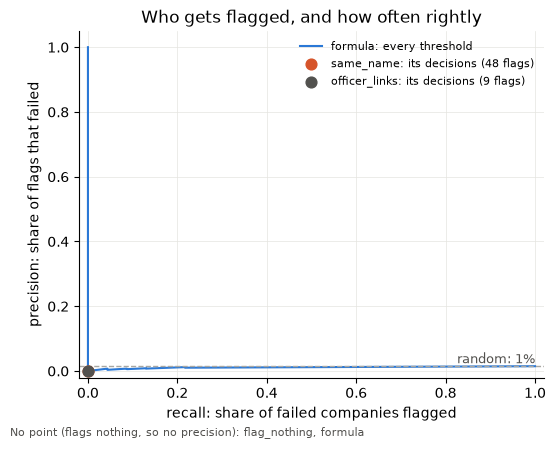

,method,companies,failed,flags,false_flags,misses,precision,recall,not_enough_evidence,pr_auc
0,flag_nothing,1552,23,0,0,23,NaN,0.0,0.000000,NaN
1,same_name,1552,23,48,48,23,0.0,0.0,0.000000,NaN
2,officer_links,1552,23,9,9,23,0.0,0.0,0.000000,NaN
3,formula,1552,23,0,0,23,NaN,0.0,0.000644,0.013584


In [18]:
# 107: precision against recall. Ours as a curve over every threshold of p_fail, each method's decisions as a point.
all_decisions = pd.concat([baseline_decisions, our_decisions], ignore_index=True)
scores = evaluate.score_methods(all_decisions, judged)
interface.display_png(interface.pr_figure(all_decisions, judged, scores))
scores

*Precision is the share of flags that really failed; recall is the share of failures that got flagged. Up and to the right is better. The dashed line is what flagging at random gives.*

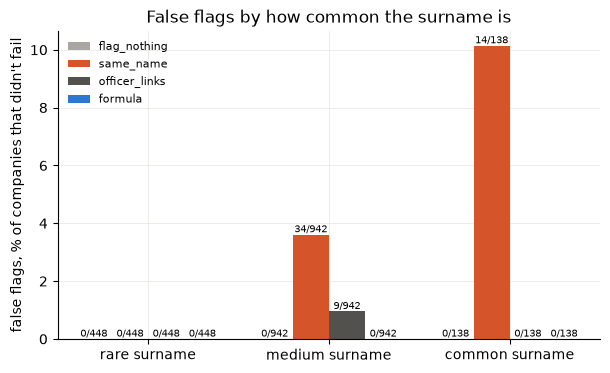

,method,band,companies,not_failed,flags,false_flags,false_flag_rate
0,flag_nothing,rare,457,448,0,0,0.000000
1,flag_nothing,medium,955,942,0,0,0.000000
2,flag_nothing,common,139,138,0,0,0.000000
3,same_name,rare,457,448,0,0,0.000000
4,same_name,medium,955,942,34,34,0.036093
5,same_name,common,139,138,14,14,0.101449
6,officer_links,rare,457,448,0,0,0.000000
7,officer_links,medium,955,942,9,9,0.009554
8,officer_links,common,139,138,0,0,0.000000
9,formula,rare,457,448,0,0,0.000000


In [19]:
# 108: false flags per name-commonness band, for ours and the three baselines, with the counts on the bars.
bands = evaluate.company_bands(mentions, claims, evaluate.name_commonness(mentions))
by_band = evaluate.false_flags_by_band(all_decisions, judged, bands)
interface.display_png(interface.false_flag_figure(by_band))
by_band

*Each bar is false flags out of the companies in that band that didn't fail. Our main claim is that the same-name rule's bar grows with how common the surname is, and ours doesn't. Added in review: here our decision layer flags no company at all (the table above), so its bar is flat for that reason, not because it handles common surnames better.*

9,171 labelled validation pairs


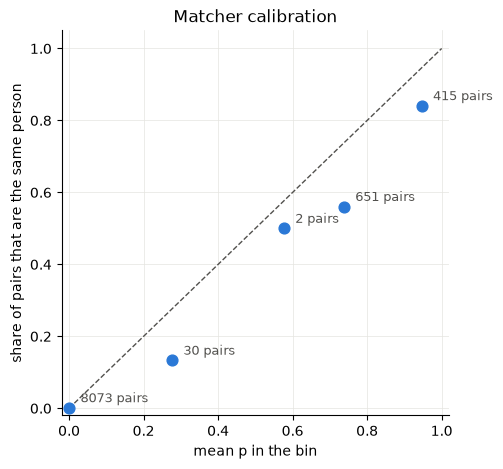

In [20]:
# 108: is the matcher's match score a probability? Its score against the share of pairs with the same officer id,
# on the labelled validation pairs, which the matcher never learned from.
held_out = labelled[labelled["split"] == "validation"].reset_index(drop=True)
if held_out.empty:   # the tiny world has no validation pairs: its training pairs, only to check that the plot draws
    held_out = labelled.reset_index(drop=True)
held_out_p = resolve.match_probability(model, resolve.pair_features(held_out, mentions))
print(f"{len(held_out):,} labelled validation pairs")
interface.display_png(interface.reliability_figure(held_out_p, held_out["label"]))

*On the dashed line, the match score means what it says: of the pairs scored about 0.6, about 60% would have the same officer id. A dot below the line means the score is too sure. The number next to each dot is how many pairs it rests on. The full check is card #88 (`notebooks/cristiano_calibration.ipynb`).*

In [21]:
# Each method's link to an earlier insolvent company, next to how the validation companies did
def failure_by_link(part, to_insolvent):
    """Per method: how many of the companies it links to an earlier insolvent company failed, and how many of the rest."""
    failed = part.set_index("company_id")["failed"]
    rows = []
    for method in METHODS:
        linked = failed.index.isin(to_insolvent.loc[to_insolvent[method], "company_id"])
        rows.append({"method": method,
                     "failed, linked to an earlier insolvent company": real_slice.rate(int(failed[linked].sum()), int(linked.sum())),
                     "failed, not linked": real_slice.rate(int(failed[~linked].sum()), int((~linked).sum()))})
    return pd.DataFrame(rows).set_index("method")


failure_by_link(validation, to_insolvent)

,"failed, linked to an earlier insolvent company","failed, not linked"
method,,
same name,2 of 219: 1% (0-3%),21 of 1333: 2% (1-2%)
officer links,0 of 42: 0% (0-8%),23 of 1510: 2% (1-2%)
matcher,0 of 105: 0% (0-4%),23 of 1447: 2% (1-2%)


**What it shows.** Under the main label an insolvent past does not predict that the new company fails. The line is nearly flat: the line gives 1.4% at P(predecessor) = 0 and 1.8% at P(predecessor) = 1. In validation 18 of 1,065 companies with P(predecessor) = 0 failed (2%), and 0 of the 105 above 0.5 (interval 0–4%): too few failures to see a difference either way. Both ends of the line are under the CLEAR threshold of 10%, so the decision layer clears 1,551 of the 1,552 validation companies (the other one has no director records: NOT ENOUGH EVIDENCE) and never flags. Its PR-AUC, 0.014, is no better than the share that failed, 0.015: on failure, the decision layer does no better than flag nothing.

The baselines do worse: with their 3-year window the same-name rule flags 48 validation companies and officer links 9, and none of them failed. The same-name rule's false flags grow with how common the surname is: 0 of 448 honest companies with a rare surname, 34 of 942 with a medium one (3.6%), 14 of 138 with a common one (10.1%). Officer links falsely flag 9 of 942 in the medium band (1.0%) and none elsewhere. And for every method, a director's link to an earlier insolvent company doesn't go with failure (the table just above: of the matcher's 105 linked companies, 0 failed).

So predicting failure can't be our headline (decision note "A strike-off counts only after real accounts"); the warning is. It tells a supplier that a director's record matches an earlier insolvent company, which is worth a check before giving credit, and the evidence picture in the Demo shows why.

## The test set, opened once (card #45)
Everything above was built and chosen on the companies formed in 2021. The companies formed in 2022 are the test set: their files were dropped before the adapter ran. The cell below is the only place that reads them, and only when `OPEN_TEST` is set to `True`. That happens once, after the feature freeze (Evaluation Protocol).

When it runs, it loads the crawl again with the 2022 companies in it, lets blocking propose the pairs, and scores them with **the matcher trained above**. Nothing is fitted or chosen here: the same matcher, the same bar of 0.5, the same two simple rules, the same tables as in the Evaluation section, now for the 2022 companies. While the switch is off it prints one line.


In [22]:
OPEN_TEST = False   # card #45: set to True for the one test run. After that run, change nothing above.

if not OPEN_TEST:
    print("The test set is closed: no company formed in 2022 has been judged in this run.")
elif not raw:
    print("No crawl in data/raw on this computer, so there is no test set to open.")
else:
    with warnings.catch_warnings(record=True) as caught:   # as in the Data section: the warnings without their lists
        warnings.simplefilter("always")
        all_mentions, all_claims, all_labels, all_left_out = real_slice.slice_from_raw(
            adapter.load_raw(), numbers + sorted(test_numbers))
    for warning in caught:
        print("adapter warning:", str(warning.message).split(":")[0])
    test = all_labels[all_labels["split"] == "test"]
    print(f"{len(test)} test companies (formed in 2022), {int(test['failed'].sum())} of them failed | left out (no label):",
          pd.Series(all_left_out).value_counts().to_dict() if all_left_out else "none")

    # The matcher from the Model section scores the pairs. It never saw a pair with a 2022 director in it.
    all_scored = resolve.scored_pairs(model, resolve.candidate_pairs(all_mentions), all_mentions)
    test_links = held_out_links(test, all_mentions, all_claims, all_scored)
    test_to_insolvent = test_links[test_links["insolvent"]]
    all_bands = evaluate.name_commonness(all_mentions)

    print("\nTEST. Links to an earlier INSOLVENT company (what the warning is about):")
    display(method_table(test_to_insolvent))
    print("TEST. Links to any earlier record:")
    display(method_table(test_links))
    print("TEST. Links to an earlier insolvent company, per name-commonness band:")
    display(real_slice.links_by_band(test_to_insolvent, all_bands))
    print("TEST. Links to any earlier record, per band:")
    display(real_slice.links_by_band(test_links, all_bands))
    print("TEST. Each method's link to an earlier insolvent company, next to how the test companies did:")
    display(failure_by_link(test, test_to_insolvent))

The test set is closed: no company formed in 2022 has been judged in this run.


## Demo
One company number in, the warning out. The company is the validation company with the highest P(predecessor). Then the picture of its evidence: solid lines are on the register; dashed lines are the matcher's guesses that two records are one person, with how sure it is in words. Directors appear under pseudonyms, companies by number only. The decision layer's answer comes with it. On this data it clears nearly every company (side result above), so the warning, not the decision, is the output to read.

WARNING for 13668751: a director's record matches an earlier company that went insolvent (03250164, match score 0.95): check before giving credit.

13668751: CLEAR
13668751 may share a director with 03250164, an earlier company that went insolvent (match score 0.95 out of 1): its 2% chance of failing within two years is low enough to clear.


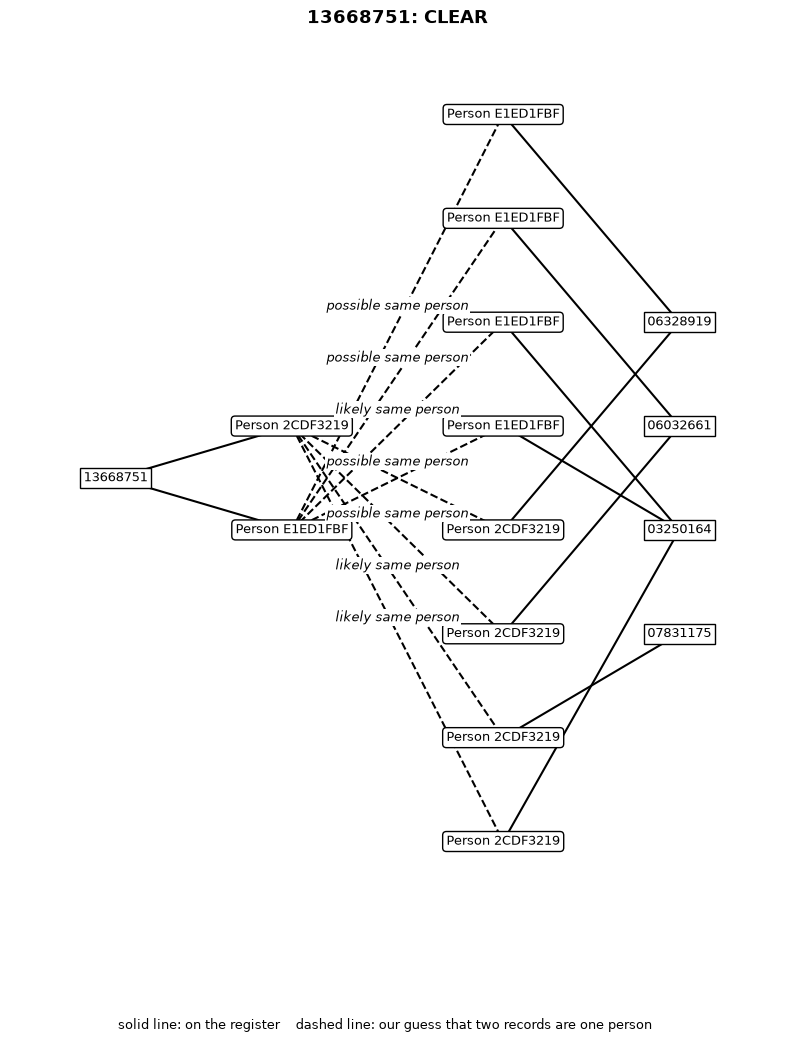

,line,from,to,says,how sure,p,source,record or depends on,check first
0,solid (fact),Person 2CDF3219,13668751,director of,on the register,NaN,companies_house,data/raw/officers/13668751.json#0@8d864f8bdf13...,
1,solid (fact),Person E1ED1FBF,13668751,director of,on the register,NaN,companies_house,data/raw/officers/13668751.json#1@8d864f8bdf13...,
2,solid (fact),Person E1ED1FBF,06328919,director of,on the register,NaN,companies_house,data/raw/officers/06328919.json#1@89c11fdca5f1...,
3,solid (fact),Person E1ED1FBF,06032661,director of,on the register,NaN,companies_house,data/raw/officers/06032661.json#1@278743b34149...,
4,solid (fact),Person E1ED1FBF,03250164,director of,on the register,NaN,companies_house,data/raw/officers/03250164.json#1@9c76726efaec...,
5,solid (fact),Person E1ED1FBF,03250164,director of,on the register,NaN,companies_house,data/raw/officers/03250164.json#7@9c76726efaec...,
6,solid (fact),Person 2CDF3219,06328919,director of,on the register,NaN,companies_house,data/raw/officers/06328919.json#3@89c11fdca5f1...,
7,solid (fact),Person 2CDF3219,06032661,director of,on the register,NaN,companies_house,data/raw/officers/06032661.json#4@278743b34149...,
8,solid (fact),Person 2CDF3219,07831175,director of,on the register,NaN,companies_house,data/raw/officers/07831175.json#0@9b4632300fc0...,
9,solid (fact),Person 2CDF3219,03250164,director of,on the register,NaN,companies_house,data/raw/officers/03250164.json#6@9c76726efaec...,


In [23]:
example = p_pred.loc[judged["company_id"]].sort_values(ascending=False, kind="stable").index[0]
found = matches[example]
best = None if found is None or found.empty else found.loc[found["p"].idxmax()]
if best is not None and best["p"] >= 0.5:   # the warning uses the Evaluation's bar: a match score of 0.5 or more
    print(f"WARNING for {example}: a director's record matches an earlier company that went insolvent "
          f"({best['predecessor']}, match score {best['p']:.2f}): check before giving credit.\n")
else:
    print(f"{example}: no warning. No director's record matches an earlier insolvent company "
          "with a match score of 0.5 or more.\n")

# Company names are real, so the picture shows company numbers; people keep their pseudonyms (display_name)
masked = mentions.assign(display_name=mentions["display_name"].where(mentions["kind"] == "person", mentions["company_number"]))
decisions = pd.DataFrame([decide.decide(example, found, line, costs)], columns=ev.DECISION_COLS)
row, fig, table = interface.show(example, masked, claims, matches, decisions)

In [24]:
# A company outside our data gets a polite answer, not an error
interface.show("00000006", masked, claims, matches, decisions)

Sorry, 00000006 isn't one of the companies we have data for, so we can't judge it. Check the number: we cover construction companies (SIC 41-43) formed in 2021 and 2022.


**What if someone checks the match by hand?** `interface.what_if` lets a person confirm a match (its score becomes 1) or reject it (0); every other match stays as it was. Then the decision layer runs again. Below, the strongest match is rejected.

In [25]:
if found is not None and not found.empty:
    strongest = int(found["p"].to_numpy().argmax())   # its number in the evidence table above
    after = decide.decide(example, interface.what_if(found, reject=[strongest]), line, costs)
    print("before:", row["decision"], f"   after rejecting match {strongest}:", after["decision"])
    print(after["reason"])

before: CLEAR    after rejecting match 2: CLEAR
13668751 may share a director with 03250164, an earlier company that went insolvent (match score 0.95 out of 1): its 2% chance of failing within two years is low enough to clear.


**What if the costs were different?** The thresholds come from three costs the team chose: a missed case 10, a wrong flag 2, asking someone to check 1. Move a slider to see the thresholds and the decision move; Reset goes back to the agreed costs. Sliders only work when the notebook runs, so the line below them shows the agreed costs for anyone reading it on GitHub.

In [26]:
interface.cost_sliders(example, found, line, costs, decide.decide, decide.thresholds)

Costs: missed case 10, wrong flag 2, asking 1. Clear at or below 10%, flag at or above 50%. 13668751: CLEAR


## Where it fails
1. **Failure can't be predicted from this data.** Under the main label an insolvent past doesn't go with more failures, and failures are few (77 in train, 23 in validation), so the decision layer clears nearly every company and never flags (side result above). Liquidation or administration alone is rarer still: 15 training cases and 1 in validation.
2. **Unconfirmed links aren't judged yet.** The officer id is our only automatic check, and the register sometimes gives one person two ids. Until the hand check (#89) gives its verdicts, an unconfirmed link can be a namesake or the same person, so precision against the register is a lower bound.
3. **The match score is too sure at the top** (card #88's calibration check), so the Demo's score ranks how likely a match is; it doesn't say how often such a match is right.
4. **The matcher learns the register's mistakes.** Its labels come from officer ids, so where the register split one person, label 0 is wrong, and the matcher is taught to miss exactly those people.
5. **The crawl sees part of each history.** It reads only part of each officer's appointment list and follows a limited number of same-name officers per director, so some earlier companies are never seen: links can be missing, never added.
6. **One identity per director isn't wired in yet.** P(predecessor) still uses the formula, which counts two records of one earlier person twice (Model section).
7. **Only construction companies formed in 2021 so far.** Other sectors are untested, and the test year, 2022, runs once with card #45.

In [27]:
print(f"The whole notebook ran in {(time.perf_counter() - started) / 60:.1f} minutes.")

The whole notebook ran in 5.9 minutes.
